# Hospital Data Analysis — Length of Stay, Readmissions & Cost

**Goal:** answer practical hospital-management questions from de-identified admissions data and feed a dashboard.

| # | Business question |
|---|---|
| Q1 | How is the hospital doing at a glance? (admissions, average stay, readmission rate, cost) |
| Q2 | Who is being admitted, and when? |
| Q3 | Which patient groups and conditions stay longer? |
| Q4 | Which patients are more likely to return within 30 days? |
| Q5 | Which departments, conditions and admission types cost the most? |

> **Data & ethics:** the dataset is synthetic and fully de-identified (see `data/DATA_DICTIONARY.md`). Findings describe patterns in data — not medical advice and not proof of cause.

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = ROOT / "reports" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
OUT = ROOT / "data" / "processed"

sns.set_theme(style="whitegrid", context="notebook")
BLUE, GREY, RED = "#2a6f97", "#9aa5b1", "#c8553d"
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.spines.top": False, "axes.spines.right": False})

def save(fig, name):
    fig.tight_layout(); fig.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")

df = pd.read_csv(OUT / "hospital_admissions_clean.csv", parse_dates=["admission_date", "discharge_date"])
elig = df[df.readmit_eligible]
print(f"{len(df):,} admissions | {df.patient_id.nunique():,} patients | {df.admission_date.min():%d %b %Y} – {df.admission_date.max():%d %b %Y}")
df.head()

10,209 admissions | 7,200 patients | 01 Jan 2023 – 31 Dec 2024


,admission_id,patient_id,admission_date,discharge_date,admission_year,admission_month,admission_weekday,age,age_group,age_imputed,...,los_band,icu_days,discharge_disposition,total_cost,cost_per_day,cost_corrected,high_cost,days_to_next_admission,readmit_eligible,readmitted_30d
0,A200000,P103796,2023-01-01,2023-01-04,2023,2023-01,Sunday,51,50-64,False,...,2-3 days,0,Home with Care,187800.0,62600.0,False,False,NaN,True,False
1,A200001,P106393,2023-01-01,2023-01-08,2023,2023-01,Sunday,24,18-34,False,...,4-7 days,0,Home,48370.0,6910.0,False,False,NaN,True,False
2,A200002,P102155,2023-01-01,2023-01-13,2023,2023-01,Sunday,49,35-49,False,...,8-14 days,0,Left Against Advice,98730.0,8227.5,False,False,11.0,True,True
3,A200003,P102124,2023-01-01,2023-01-11,2023,2023-01,Sunday,82,80+,False,...,8-14 days,0,Home,121360.0,12136.0,False,False,NaN,True,False
4,A200004,P104177,2023-01-01,2023-01-04,2023,2023-01,Sunday,35,35-49,False,...,2-3 days,0,Home,64110.0,21370.0,False,False,NaN,True,False


## 0. Data quality — what cleaning changed

In [2]:
log = pd.read_csv(OUT / "cleaning_log.csv")
log

,step,rows_affected,detail
0,Load raw file,10362,all columns read as text first
1,Remove exact duplicate rows,153,double-loaded records
2,Check duplicate admission_id,0,should be 0 after removing exact duplicates
3,Standardise gender,1033,M/male/MALE/F/female -> Male/Female
4,Standardise department,351,"case, spaces and 'Gen.' abbreviation fixed"
5,Fill missing insurance_type,306,"labelled 'Unknown' (kept, not dropped)"
6,Fill missing admission_source,204,"labelled 'Unknown' (kept, not dropped)"
7,Fill missing discharge_disposition,102,"labelled 'Unknown' (kept, not dropped)"
8,Parse mixed date formats,510,DD/MM/YYYY rows converted to ISO
9,Fix discharge before admission,15,dates were swapped at entry; swapped back


In [3]:
# Remaining checks after cleaning
checks = {
    "duplicate admission_id": int(df.admission_id.duplicated().sum()),
    "negative length of stay": int((df.length_of_stay < 0).sum()),
    "missing total_cost (excluded from cost metrics)": int(df.total_cost.isna().sum()),
    "ages imputed": int(df.age_imputed.sum()),
    "readmission-eligible stays": int(df.readmit_eligible.sum()),
    "class balance: readmitted (%)": round(elig.readmitted_30d.mean() * 100, 1),
}
pd.Series(checks, name="value").to_frame()

,value
duplicate admission_id,0.0
negative length of stay,0.0
missing total_cost (excluded from cost metrics),153.0
ages imputed,216.0
readmission-eligible stays,9412.0
class balance: readmitted (%),13.4


**Class imbalance note:** only ~13% of eligible stays are readmissions. Any model or comparison must look at rates within groups, not raw counts, and accuracy alone would be misleading (predicting "no readmission" for everyone is ~87% accurate).

## Q1. Hospital performance at a glance

In [4]:
kpi = {
    "admissions": len(df),
    "unique_patients": df.patient_id.nunique(),
    "avg_los_days": round(df.length_of_stay.mean(), 2),
    "median_los_days": float(df.length_of_stay.median()),
    "readmission_rate_30d_pct": round(elig.readmitted_30d.mean() * 100, 1),
    "avg_cost_per_stay_inr": round(df.total_cost.mean()),
    "total_cost_inr_crore": round(df.total_cost.sum() / 1e7, 2),
    "mortality_pct": round((df.discharge_disposition == "Expired").mean() * 100, 2),
    "emergency_share_pct": round((df.admission_type == "Emergency").mean() * 100, 1),
}
by_year = df.groupby("admission_year").agg(admissions=("admission_id", "size"), avg_los=("length_of_stay", "mean"),
                                           avg_cost=("total_cost", "mean")).round(2)
by_year["readmit_rate_pct"] = (elig.groupby("admission_year").readmitted_30d.mean() * 100).round(1)
json.dump(kpi, open(OUT / "kpis.json", "w"), indent=2)
display(pd.Series(kpi).to_frame("value")); by_year

,value
admissions,10209.00
unique_patients,7200.00
avg_los_days,6.37
median_los_days,5.00
readmission_rate_30d_pct,13.40
avg_cost_per_stay_inr,108971.00
total_cost_inr_crore,109.58
mortality_pct,1.67
emergency_share_pct,53.60


,admissions,avg_los,avg_cost,readmit_rate_pct
admission_year,,,,
2023,4531,6.14,107147.32,12.1
2024,5678,6.56,110430.65,14.6


## Q2. Who is admitted, and when?

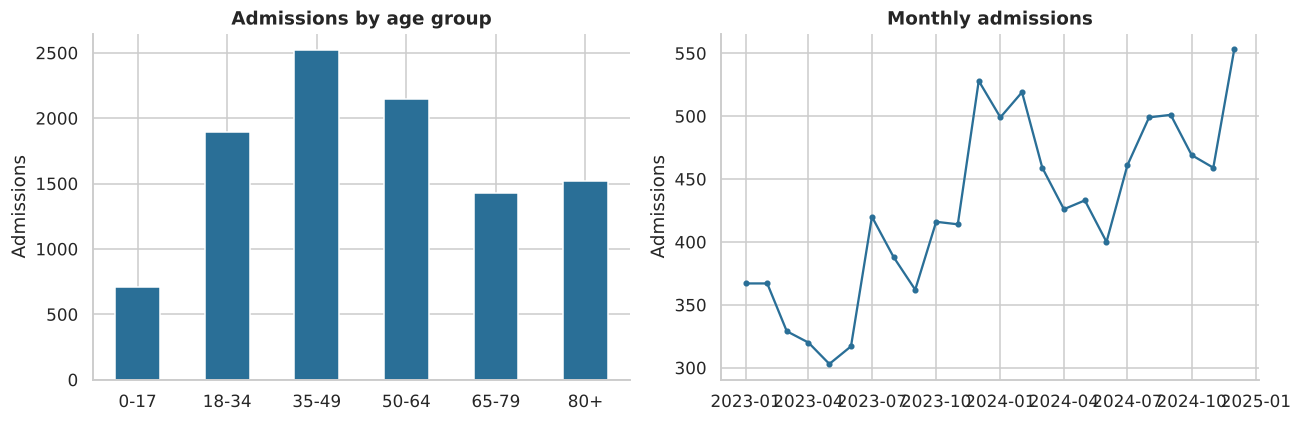

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ag = df.age_group.value_counts().reindex(["0-17","18-34","35-49","50-64","65-79","80+"])
ag.plot.bar(ax=ax[0], color=BLUE); ax[0].set(title="Admissions by age group", xlabel="", ylabel="Admissions"); ax[0].tick_params(axis="x", rotation=0)
m = df.groupby(df.admission_date.dt.to_period("M")).size(); m.index = m.index.to_timestamp()
ax[1].plot(m.index, m.values, color=BLUE, marker="o", ms=3); ax[1].set(title="Monthly admissions", ylabel="Admissions")
save(fig, "q2_admissions_age_month")

In [6]:
season = df.groupby(df.admission_date.dt.month).size() / 2  # 2 years -> avg per month
wd = df.admission_weekday.value_counts().reindex(["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"])
mix = pd.crosstab(df.department, df.admission_type, normalize="index").mul(100).round(1)
print("Avg admissions by calendar month:", season.round(0).astype(int).to_dict())
print("Winter (Dec-Feb) vs summer (May-Jun) avg/month:",
      round(season[[12,1,2]].mean()), "vs", round(season[[5,6]].mean()))
display(df.gender.value_counts(normalize=True).mul(100).round(1).to_frame("% of admissions"))
display(df.admission_source.value_counts(normalize=True).mul(100).round(1).to_frame("% of admissions"))
mix

Avg admissions by calendar month: {1: 433, 2: 443, 3: 394, 4: 373, 5: 368, 6: 358, 7: 440, 8: 444, 9: 432, 10: 442, 11: 436, 12: 540}
Winter (Dec-Feb) vs summer (May-Jun) avg/month: 472 vs 363


,% of admissions
gender,
Female,51.7
Male,48.3


,% of admissions
admission_source,
Emergency Dept,54.5
Physician Referral,34.9
Transfer,8.6
Unknown,2.0


admission_type,Elective,Emergency,Urgent
department,,,
Cardiology,10.0,62.0,28.0
Endocrinology,8.8,61.9,29.4
General Medicine,11.4,60.3,28.3
General Surgery,35.9,40.6,23.5
Nephrology,10.7,59.7,29.7
Neurology,10.6,60.0,29.5
Obstetrics,40.3,34.0,25.7
Orthopedics,43.7,33.4,22.9
Pulmonology,9.3,62.9,27.8


## Q3. Which patient groups and conditions stay longer?

,mean,median
age_group,,
0-17,4.08,3.0
18-34,3.90,3.0
35-49,4.97,4.0
50-64,6.59,6.0
65-79,8.07,7.0
80+,10.94,9.0


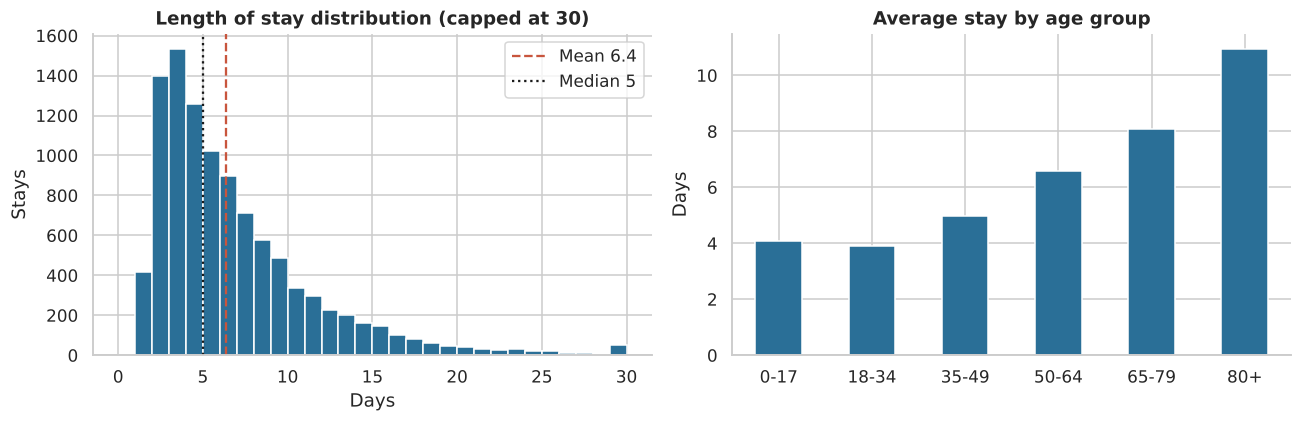

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(df.length_of_stay.clip(upper=30), bins=30, color=BLUE)
ax[0].axvline(df.length_of_stay.mean(), color=RED, ls="--", label=f"Mean {df.length_of_stay.mean():.1f}")
ax[0].axvline(df.length_of_stay.median(), color="k", ls=":", label=f"Median {df.length_of_stay.median():.0f}")
ax[0].set(title="Length of stay distribution (capped at 30)", xlabel="Days", ylabel="Stays"); ax[0].legend()
los_age = df.groupby("age_group").length_of_stay.agg(["mean","median"]).reindex(["0-17","18-34","35-49","50-64","65-79","80+"])
los_age["mean"].plot.bar(ax=ax[1], color=BLUE); ax[1].set(title="Average stay by age group", xlabel="", ylabel="Days"); ax[1].tick_params(axis="x", rotation=0)
save(fig, "q3_los_distribution_age")
los_age.round(2)

,stays,avg_los,median_los,pct_icu
primary_diagnosis,,,,
Stroke,587,11.9,10.0,29.3
Sepsis,694,10.9,9.0,44.7
Heart Failure,862,10.1,9.0,13.6
Acute Myocardial Infarction,618,8.4,7.0,42.7
Kidney Disease,843,8.4,7.0,3.6
COPD Exacerbation,810,7.4,6.0,2.7
Pneumonia,556,6.8,6.0,4.0
Diabetes Complications,763,5.1,4.0,2.5
Fracture,534,5.0,4.0,3.9


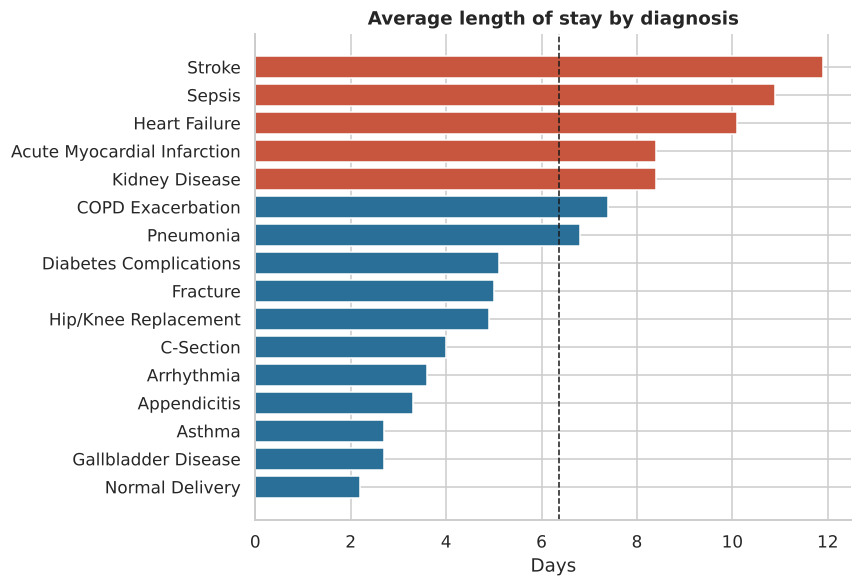

In [8]:
los_diag = df.groupby("primary_diagnosis").agg(stays=("admission_id","size"), avg_los=("length_of_stay","mean"),
                                               median_los=("length_of_stay","median"), pct_icu=("icu_days", lambda s: (s>0).mean()*100)
                                               ).sort_values("avg_los", ascending=False).round(1)
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(los_diag.index[::-1], los_diag.avg_los[::-1], color=[RED if v >= los_diag.avg_los.quantile(.75) else BLUE for v in los_diag.avg_los[::-1]])
ax.axvline(df.length_of_stay.mean(), color="k", ls="--", lw=1); ax.set(title="Average length of stay by diagnosis", xlabel="Days")
save(fig, "q3_los_by_diagnosis")
los_diag.to_csv(OUT / "summary_los_by_diagnosis.csv"); los_diag

In [9]:
display(df.groupby("admission_type").length_of_stay.agg(["mean","median","size"]).round(2))
display(df.groupby("comorbidity_band").length_of_stay.agg(["mean","median","size"]).round(2))
# Adjusted view: does age still matter once diagnosis, comorbidities and admission type are held constant?
los_model = smf.ols("np.log1p(length_of_stay) ~ C(age_group, Treatment('35-49')) + comorbidity_count + C(admission_type) + C(primary_diagnosis)", data=df).fit()
eff = (np.exp(los_model.params[[i for i in los_model.params.index if ("age_group" in i or "comorbidity" in i or "admission_type" in i)]]) - 1).mul(100).round(1)
print(f"R² = {los_model.rsquared:.2f}. % change in length of stay (approx), holding diagnosis constant:")
eff.to_frame("% change vs baseline")

,mean,median,size
admission_type,,,
Elective,5.02,4.0,1978
Emergency,7.00,6.0,5472
Urgent,6.10,5.0,2759


,mean,median,size
comorbidity_band,,,
0,4.32,3.0,3455
1-2,6.14,5.0,4284
3-4,9.01,8.0,1819
5+,11.43,10.0,651


R² = 0.59. % change in length of stay (approx), holding diagnosis constant:


,% change vs baseline
"C(age_group, Treatment('35-49'))[T.0-17]",-1.8
"C(age_group, Treatment('35-49'))[T.18-34]",-1.5
"C(age_group, Treatment('35-49'))[T.50-64]",4.6
"C(age_group, Treatment('35-49'))[T.65-79]",17.1
"C(age_group, Treatment('35-49'))[T.80+]",39.1
C(admission_type)[T.Emergency],10.4
C(admission_type)[T.Urgent],0.2
comorbidity_count,7.2


## Q4. Who is more likely to be readmitted within 30 days?

,stays,readmissions,rate_pct
primary_diagnosis,,,
Heart Failure,772,207,26.8
COPD Exacerbation,760,199,26.2
Kidney Disease,776,187,24.1
Acute Myocardial Infarction,572,113,19.8
Sepsis,584,102,17.5
Stroke,515,86,16.7
Diabetes Complications,718,108,15.0
Pneumonia,525,69,13.1
Arrhythmia,476,36,7.6


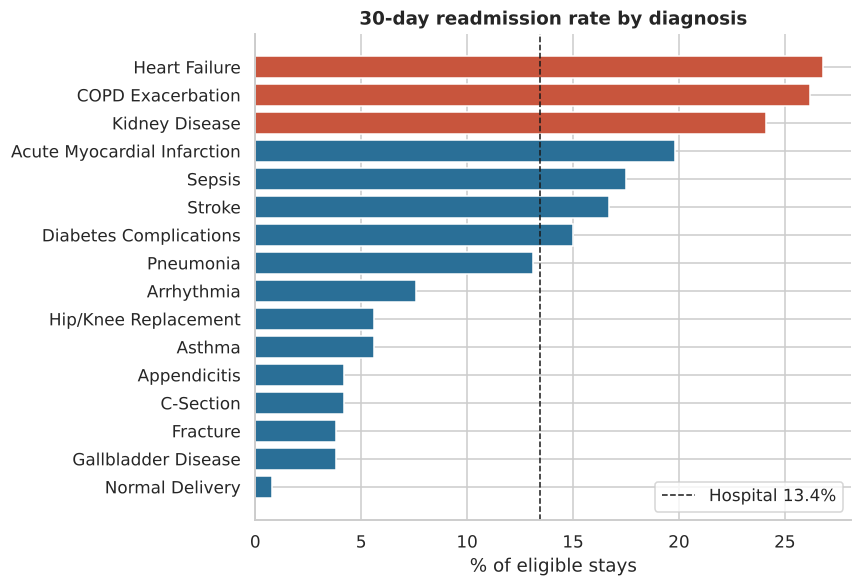

In [10]:
def rate(col, order=None):
    t = elig.groupby(col).agg(stays=("readmitted_30d","size"), readmissions=("readmitted_30d","sum"))
    t["rate_pct"] = (t.readmissions / t.stays * 100).round(1)
    return t.reindex(order) if order else t.sort_values("rate_pct", ascending=False)

r_diag = rate("primary_diagnosis"); r_diag.to_csv(OUT / "summary_readmit_by_diagnosis.csv")
overall = elig.readmitted_30d.mean() * 100
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(r_diag.index[::-1], r_diag.rate_pct[::-1], color=[RED if v > overall*1.5 else BLUE for v in r_diag.rate_pct[::-1]])
ax.axvline(overall, color="k", ls="--", lw=1, label=f"Hospital {overall:.1f}%"); ax.legend(loc="lower right")
ax.set(title="30-day readmission rate by diagnosis", xlabel="% of eligible stays")
save(fig, "q4_readmit_by_diagnosis")
r_diag

,stays,readmissions,rate_pct
age_group,,,
0-17,656,38,5.8
18-34,1759,117,6.7
35-49,2354,213,9.0
50-64,1963,269,13.7
65-79,1314,241,18.3
80+,1366,386,28.3


,stays,readmissions,rate_pct
prior_band,,,
0,6679,692,10.4
1,1891,314,16.6
2,556,148,26.6
3+,286,110,38.5


,stays,readmissions,rate_pct
discharge_disposition,,,
Left Against Advice,409,106,25.9
Skilled Nursing/Rehab,1168,261,22.3
Home,6543,750,11.5
Home with Care,1199,137,11.4
Unknown,93,10,10.8


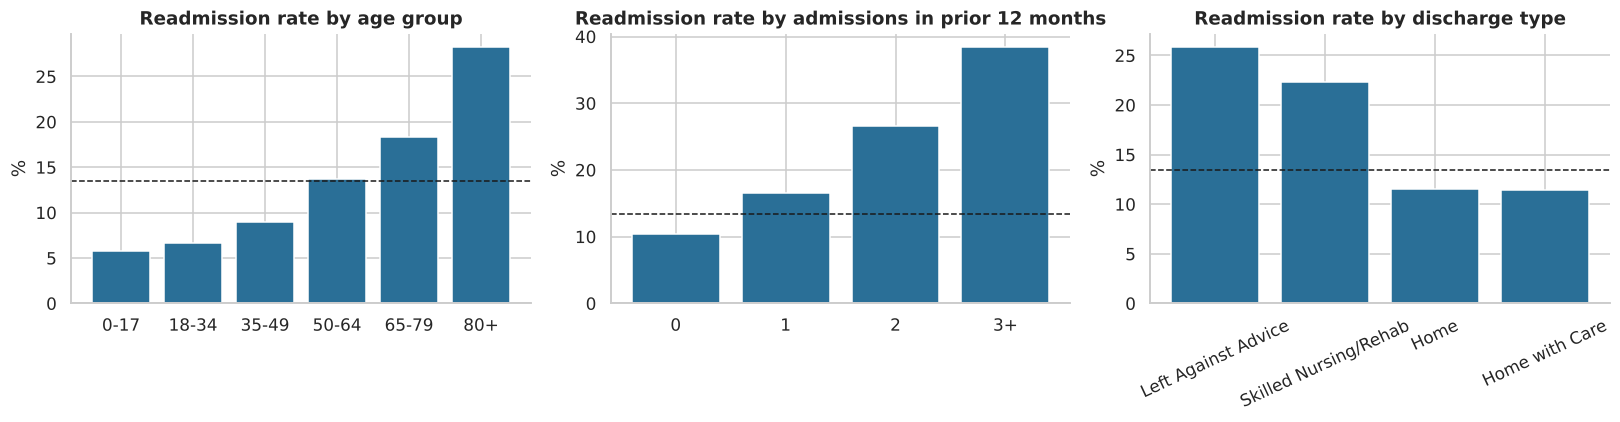

In [11]:
elig = elig.assign(prior_band=pd.cut(elig.prior_admissions_12m, [-1,0,1,2,99], labels=["0","1","2","3+"]).astype(str))
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, (col, order, title) in zip(ax, [("age_group", ["0-17","18-34","35-49","50-64","65-79","80+"], "by age group"),
                                      ("prior_band", ["0","1","2","3+"], "by admissions in prior 12 months"),
                                      ("discharge_disposition", None, "by discharge type")]):
    t = rate(col, order); t = t[t.index != "Unknown"]
    a.bar(t.index.astype(str), t.rate_pct, color=BLUE); a.axhline(overall, color="k", ls="--", lw=1)
    a.set(title=f"Readmission rate {title}", ylabel="%"); a.tick_params(axis="x", rotation=25 if col=="discharge_disposition" else 0)
save(fig, "q4_readmit_drivers")
display(rate("age_group", ["0-17","18-34","35-49","50-64","65-79","80+"]))
display(rate("prior_band", ["0","1","2","3+"]))
rate("discharge_disposition")

In [12]:
# Which factors matter when looked at together? Logistic regression (association, not causation)
m = smf.logit("readmitted_30d ~ age + comorbidity_count + prior_admissions_12m + length_of_stay + C(admission_type) "
              "+ C(discharge_disposition, Treatment('Home')) + C(insurance_type)",
              data=elig[elig.discharge_disposition != "Unknown"].assign(readmitted_30d=lambda d: d.readmitted_30d.astype(int))).fit(disp=0)
ci = np.exp(m.conf_int()); orr = pd.DataFrame({"odds_ratio": np.exp(m.params), "ci_low": ci[0], "ci_high": ci[1], "p_value": m.pvalues}).drop("Intercept").round(3)
orr.to_csv(OUT / "readmission_odds_ratios.csv")
print(f"Pseudo R² = {m.prsquared:.3f}  (n = {int(m.nobs):,})")
orr.sort_values("odds_ratio", ascending=False)

Pseudo R² = 0.099  (n = 9,319)


,odds_ratio,ci_low,ci_high,p_value
"C(discharge_disposition, Treatment('Home'))[T.Left Against Advice]",2.887,2.261,3.685,0.000
C(admission_type)[T.Emergency],1.553,1.288,1.872,0.000
C(admission_type)[T.Urgent],1.488,1.213,1.825,0.000
"C(discharge_disposition, Treatment('Home'))[T.Skilled Nursing/Rehab]",1.430,1.203,1.699,0.000
prior_admissions_12m,1.355,1.274,1.443,0.000
comorbidity_count,1.171,1.119,1.225,0.000
length_of_stay,1.028,1.015,1.041,0.000
age,1.011,1.008,1.015,0.000
"C(discharge_disposition, Treatment('Home'))[T.Home with Care]",0.999,0.818,1.221,0.995
C(insurance_type)[T.Government Scheme],0.968,0.786,1.193,0.760


In [13]:
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split
d = elig[elig.discharge_disposition != "Unknown"].assign(y=lambda x: x.readmitted_30d.astype(int))
tr, te = train_test_split(d, test_size=0.3, random_state=0, stratify=d.y)
mm = smf.logit("y ~ age + comorbidity_count + prior_admissions_12m + length_of_stay + C(admission_type) + C(discharge_disposition) + C(primary_diagnosis)", data=tr).fit(disp=0)
p = mm.predict(te); auc = roc_auc_score(te.y, p)
te = te.assign(risk=p, decile=pd.qcut(p, 10, labels=False, duplicates="drop"))
top = te[te.decile == te.decile.max()]
print(f"Hold-out AUC = {auc:.2f}. Top-10% risk group readmission rate = {top.y.mean()*100:.1f}% vs {te.y.mean()*100:.1f}% overall; "
      f"it contains {top.y.sum()/te.y.sum()*100:.0f}% of all readmissions.")
json.dump({"auc": round(auc, 3), "top_decile_rate_pct": round(top.y.mean()*100, 1),
           "top_decile_share_of_readmissions_pct": round(top.y.sum()/te.y.sum()*100, 1)}, open(OUT / "risk_model.json", "w"), indent=2)

Hold-out AUC = 0.75. Top-10% risk group readmission rate = 41.8% vs 13.4% overall; it contains 31% of all readmissions.


## Q5. Where does the money go?

,stays,total_cost_cr,avg_cost,avg_cost_per_day,avg_los,share_of_total_pct
department,,,,,,
Cardiology,1992,32.39,164508.45,24399.98,7.91,29.6
Orthopedics,1148,20.68,182516.08,46700.79,4.98,18.9
General Medicine,1250,13.12,107053.25,12721.63,9.10,12.0
Neurology,587,10.86,188179.51,18451.16,11.86,9.9
General Surgery,1245,9.87,81208.59,32665.37,3.02,9.0
Nephrology,843,7.10,85759.47,11309.87,8.36,6.5
Pulmonology,1584,6.88,43978.05,9509.70,5.11,6.3
Obstetrics,797,5.07,64387.65,23007.08,3.10,4.6
Endocrinology,763,3.61,47710.89,10259.23,5.10,3.3


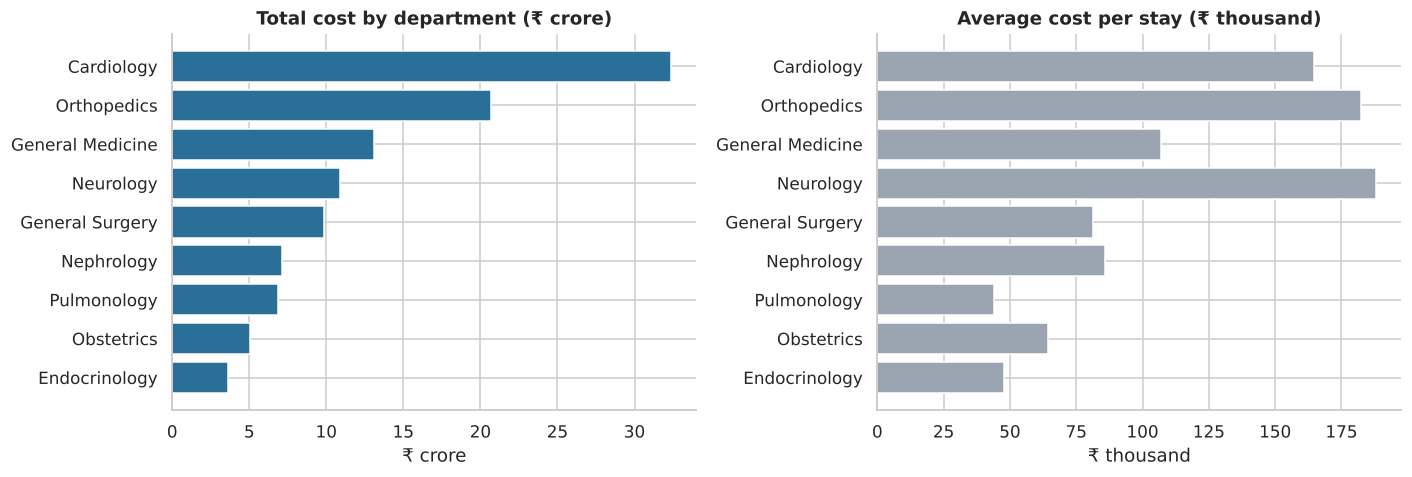

In [14]:
cost_dept = df.groupby("department").agg(stays=("admission_id","size"), total_cost_cr=("total_cost", lambda s: s.sum()/1e7),
                                         avg_cost=("total_cost","mean"), avg_cost_per_day=("cost_per_day","mean"),
                                         avg_los=("length_of_stay","mean")).sort_values("total_cost_cr", ascending=False).round(2)
cost_dept["share_of_total_pct"] = (cost_dept.total_cost_cr / cost_dept.total_cost_cr.sum() * 100).round(1)
cost_dept.to_csv(OUT / "summary_cost_by_department.csv")
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].barh(cost_dept.index[::-1], cost_dept.total_cost_cr[::-1], color=BLUE); ax[0].set(title="Total cost by department (₹ crore)", xlabel="₹ crore")
ax[1].barh(cost_dept.index[::-1], cost_dept.avg_cost[::-1]/1000, color=GREY); ax[1].set(title="Average cost per stay (₹ thousand)", xlabel="₹ thousand")
save(fig, "q5_cost_by_department")
cost_dept

In [15]:
cost_diag = df.groupby("primary_diagnosis").agg(stays=("admission_id","size"), avg_cost=("total_cost","mean"),
                                                total_cost_cr=("total_cost", lambda s: s.sum()/1e7)).sort_values("total_cost_cr", ascending=False).round(1)
cost_diag.to_csv(OUT / "summary_cost_by_diagnosis.csv")
display(cost_diag.head(8))
display(df.groupby("admission_type").agg(avg_cost=("total_cost","mean"), avg_cost_per_day=("cost_per_day","mean")).round(0))
hc = df.groupby("high_cost").agg(share_stays=("admission_id","size"), cost=("total_cost","sum"), avg_los=("length_of_stay","mean"),
                                 pct_icu=("icu_days", lambda s: (s>0).mean()*100), avg_age=("age","mean"))
hc["share_stays"] = (hc.share_stays / hc.share_stays.sum() * 100).round(1); hc["share_cost"] = (hc.cost / hc.cost.sum() * 100).round(1)
print("High-cost stays (top 10%) vs the rest:")
hc.drop(columns="cost").round(1)

,stays,avg_cost,total_cost_cr
primary_diagnosis,,,
Acute Myocardial Infarction,618,267488.7,16.4
Hip/Knee Replacement,614,250532.9,15.2
Heart Failure,862,148661.6,12.7
Stroke,587,188179.5,10.9
Sepsis,694,149768.9,10.1
Kidney Disease,843,85759.5,7.1
Appendicitis,722,80871.1,5.7
Fracture,534,104025.2,5.5


,avg_cost,avg_cost_per_day
admission_type,,
Elective,129095.0,34116.0
Emergency,103902.0,17335.0
Urgent,104580.0,20989.0


High-cost stays (top 10%) vs the rest:


,share_stays,avg_los,pct_icu,avg_age,share_cost
high_cost,,,,,
False,90.1,5.9,7.5,49.8,73.4
True,9.9,10.9,40.0,69.8,26.6


In [16]:
icu = df.assign(icu=df.icu_days > 0).groupby("icu").agg(stays=("admission_id","size"), avg_cost=("total_cost","mean"), avg_los=("length_of_stay","mean")).round(0)
readmit_cost = df[df.readmitted_30d].total_cost.sum()  # cost of index stays that were followed by readmission
next_cost = df.sort_values("admission_date").groupby("patient_id").total_cost.shift(-1)[df.readmitted_30d].sum()
print(f"Cost of readmission stays (the return visits): ₹{next_cost/1e7:.2f} crore "
      f"= {next_cost/df.total_cost.sum()*100:.1f}% of total spend")
json.dump({"readmission_stay_cost_cr": round(next_cost/1e7, 2), "readmission_cost_share_pct": round(next_cost/df.total_cost.sum()*100, 1)},
          open(OUT / "readmission_cost.json", "w"), indent=2)
icu

Cost of readmission stays (the return visits): ₹15.25 crore = 13.9% of total spend


,stays,avg_cost,avg_los
icu,,,
False,9116,96252.0,6.0
True,1093,215237.0,9.0


## Key findings (generated from the numbers above)

In [17]:
k = kpi; top_los = los_diag.index[:3].tolist(); top_r = r_diag.index[:3].tolist(); top_c = cost_dept.index[:2].tolist()
r_age = rate("age_group"); r_prior = rate("prior_band")
findings = [
 f"The hospital handled {k['admissions']:,} admissions from {k['unique_patients']:,} patients in 2023–24; average stay {k['avg_los_days']} days (median {k['median_los_days']:.0f}), "
 f"30-day readmission rate {k['readmission_rate_30d_pct']}%, average cost ₹{k['avg_cost_per_stay_inr']:,} per stay.",
 f"Stay length rises steadily with age: {los_age.loc['80+','mean']:.1f} days for 80+ vs {los_age.loc['18-34','mean']:.1f} for 18–34. Longest-stay conditions: {', '.join(top_los)}.",
 f"Readmissions concentrate in chronic conditions — {', '.join(top_r)} — each well above the {overall:.1f}% average.",
 f"Patients with 3+ admissions in the prior year are readmitted at {r_prior.loc['3+','rate_pct']}% vs {r_prior.loc['0','rate_pct']}% for first-time patients; "
 f"those who left against medical advice at {rate('discharge_disposition').loc['Left Against Advice','rate_pct']}%.",
 f"{top_c[0]} and {top_c[1]} account for {cost_dept.share_of_total_pct.iloc[:2].sum():.0f}% of total cost. The top 10% most expensive stays take {hc.loc[True,'share_cost']}% of spend.",
]
for i, f in enumerate(findings, 1): print(f"{i}. {f}")

1. The hospital handled 10,209 admissions from 7,200 patients in 2023–24; average stay 6.37 days (median 5), 30-day readmission rate 13.4%, average cost ₹108,971 per stay.
2. Stay length rises steadily with age: 10.9 days for 80+ vs 3.9 for 18–34. Longest-stay conditions: Stroke, Sepsis, Heart Failure.
3. Readmissions concentrate in chronic conditions — Heart Failure, COPD Exacerbation, Kidney Disease — each well above the 13.4% average.
4. Patients with 3+ admissions in the prior year are readmitted at 38.5% vs 10.4% for first-time patients; those who left against medical advice at 25.9%.
5. Cardiology and Orthopedics account for 48% of total cost. The top 10% most expensive stays take 26.6% of spend.


### Recommendations (for a hospital manager)
1. **Targeted discharge follow-up** for heart failure, COPD and kidney disease patients and anyone with 2+ admissions in the past year — e.g. a phone call within 72 hours and an early clinic slot. These groups are a small share of patients but a large share of readmissions.
2. **Reduce "left against advice" discharges**: review why patients leave early (cost, waiting, communication); this group is readmitted at roughly twice the average rate.
3. **Plan beds for the December peak**: December admissions run ~25% above the monthly average, while March–June is the quietest stretch; shift elective procedures and leave toward the quieter months.
4. **Review long stays in elderly patients**: early discharge planning and rehab coordination for 65+ patients, where stays are longest.
5. **Cost focus on Cardiology and Orthopedics**: review ICU use and implant/procedure costs, which drive the high-cost tail.

*Caveat: synthetic data; associations only. A real deployment would need clinical review and validation on real, governed data.*